
# Lecture 23 — Processor Pipelining

**Professor:** Dr. Janibul Bashir  
**Lecture:** [Processor Pipelining, Uniform Pipeline, Ideal Pipeline and Pipeline Diagram](https://youtu.be/zpxmj1L9Ank?utm_source=chatgpt.com)  
**Duration:** Approximately 59 minutes  
**Transcript:** Retrieved through vidIQ

---

## Lecture Overview

| Timestamp | Topic |
|---|---|
| 0:00–9:56 | Non-pipelined multi-cycle processor and idle stages |
| 9:56–20:26 | Pipelining and instruction-level parallelism |
| 20:26–30:42 | CPI, IPC and pipeline speedup derivations |
| 30:42–43:05 | Performance examples and assumptions |
| 43:05–50:18 | Ideal pipeline, uniform pipeline and dependencies |
| 50:18–59:17 | Pipeline diagrams, bubbles and introduction to hazards |

Much of the first 20 minutes repeats Lecture 22, so we'll move straight to the new reasoning and numerical questions.

---

## Part 1 — Why Pipelining Improves Performance

Imagine a **five-stage multi-cycle processor** executing five instructions.

### 1.1 Without Pipelining

- `I1` completes after 5 cycles.
- `I2` completes after 10 cycles.
- `I3` completes after 15 cycles.
- `I4` completes after 20 cycles.
- `I5` completes after 25 cycles.

Total:

$$
5\times5=\boxed{25\text{ cycles}}
$$

### 1.2 With Pipelining

These instructions overlap:

- `I1` finishes in cycle 5.
- `I2` finishes in cycle 6.
- `I3` finishes in cycle 7.
- `I4` finishes in cycle 8.
- `I5` finishes in cycle 9.

Total:

$$
5+5-1=\boxed{9\text{ cycles}}
$$

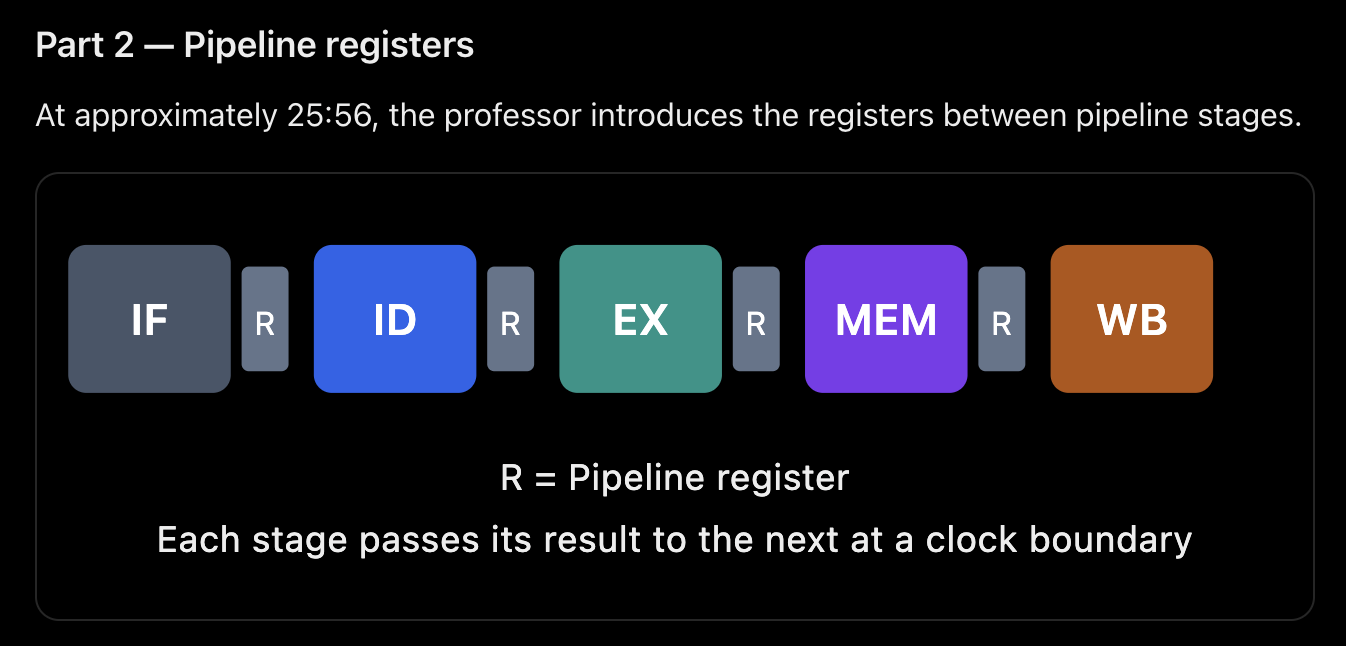

### 1.3 Instruction-Level Parallelism (ILP)

The professor calls this **Instruction-Level Parallelism (ILP)** because multiple instructions are in different execution stages simultaneously.

---

## Part 2 — Pipeline Registers

At approximately **25:56**, the professor introduces the registers between pipeline stages.

These registers are commonly called:

- `IF/ID`
- `ID/EX`
- `EX/MEM`
- `MEM/WB`



### Purpose of Pipeline Registers

They preserve intermediate results between clock cycles, allowing each stage to work on a different instruction.

> 📝 **Technical note:** The professor mentions negative-edge-triggered latches. Actual pipeline implementations can use different clocking arrangements; negative-edge triggering isn't a universal requirement.

---

## Part 3 — Deriving Pipeline Speedup

This is one of the most important numericals in Lecture 23.

### 3.1 Define the Variables

| Variable | Meaning |
|---|---|
| $n$ | Number of instructions |
| $k$ | Number of pipeline stages |
| $T$ | Duration of one clock cycle |

**Assumptions:**

- Balanced stages
- Equal clock periods
- No stalls

### 3.2 Non-Pipelined Execution Time

$$
T_{\text{nonpipe}}=nkT
$$

### 3.3 Pipelined Execution Time

$$
T_{\text{pipe}}=(n+k-1)T
$$

### 3.4 Derive the Speedup Formula

Speedup is the ratio of the original execution time to the improved execution time:

$$
S=\frac{T_{\text{nonpipe}}}{T_{\text{pipe}}}
$$

Substitute:

$$
S=\frac{nkT}{(n+k-1)T}
$$

Cancel $T$:

$$
\boxed{S=\frac{nk}{n+k-1}}
$$

### 3.5 Professor's Numerical Example

Given:

$$
n=10,\qquad k=5
$$

Substitute:

$$
S=\frac{10\times5}{10+5-1}
$$

$$
S=\frac{50}{14}=\boxed{3.57}
$$

Therefore, the pipelined processor is approximately **3.57 times faster** under these assumptions.

> 📝 **Transcript clarification:** The transcript contains a small arithmetic slip during this example. The correct denominator is **14**, not 40.

### 3.6 What Happens When the Number of Instructions Becomes Very Large?

For:

$$
n\gg k
$$

The term $k-1$ becomes negligible compared with $n$.

Therefore:

$$
S=\frac{nk}{n+k-1}\approx\frac{nk}{n}
$$

$$
\boxed{S_{\max}\rightarrow k}
$$

### Final Result

> 📌 **The theoretical maximum speedup of an ideal $k$-stage pipeline approaches $k$.**

This assumes the pipelined and non-pipelined implementations have the same clock period and no pipeline overhead or stalls.

---



# Lecture 23 — Part 4: Ideal vs Non-Ideal Pipelines and Part 5: Pipeline Diagrams

**Professor:** Dr. Janibul Bashir  
**Part 4 Transcript:** Approximately 43:05–50:18  
**Part 5 Transcript:** Approximately 50:18–57:19

---

## 1. What Is an Ideal Pipeline?

The professor describes an **ideal pipeline** using three simplifying assumptions:

1. **No instruction dependencies:** One instruction doesn't need to wait for the result of another.
2. **Uniform stage delays:** Each stage takes approximately the same amount of time.
3. **Uniform processing behavior:** Instructions fit the same pipeline structure without additional execution delays.

Under these assumptions, the pipeline can continuously accept one new instruction each cycle.

Once filled, it completes **one instruction every cycle**.

Therefore, for a single-issue ideal pipeline:

$$
\boxed{IPC_{\text{steady state}}=1}
$$

$$
\boxed{CPI_{\text{steady state}}=1}
$$

> 📌 **Important:** For a finite program, average CPI includes pipeline filling and draining overhead.

---

## 2. What Happens in a Real Pipeline?

Real instructions are not always independent.

For example:

```asm
add x5, x1, x2
sub x6, x5, x3
```

Look carefully.

The first instruction calculates:

$$
x5=x1+x2
$$

The second calculates:

$$
x6=x5-x3
$$

But the second instruction needs the value of `x5` produced by the first.

This is a **data dependency**.

If the processor tries to use the old value of `x5`, the result may be incorrect.

The pipeline must handle this dependency through techniques such as:

- **Forwarding**
- **Stalling**

When an instruction is delayed, it may create an empty pipeline slot called a **bubble**.

---

## 3. Uniform vs Non-Uniform Pipelines

These terms are slightly different from **ideal versus non-ideal**.

### 3.1 Comparison

| Feature | Uniform (Balanced) Pipeline | Non-Uniform (Unbalanced) Pipeline |
|---|---|---|
| Stage delays | Approximately equal | Different |
| Clock period | Matches the required stage delay | Determined by slowest stage |
| Efficiency | Usually higher | May contain wasted stage time |
| Example | 2, 2, 2, 2 ns | 1, 2, 4, 1 ns |

### 3.2 Numerical Example

Suppose we have four stages:

$$
d_1=1,\quad d_2=2,\quad d_3=4,\quad d_4=1\text{ ns}
$$

The clock period must accommodate the **slowest stage**:

$$
T_{\text{clk}}\geq\max(1,2,4,1)
$$

Therefore:

$$
\boxed{T_{\text{clk}}\geq4\text{ ns}}
$$

Even though Stage 1 finishes in **1 ns**, it cannot hand its output to the next clocked stage until the appropriate clock boundary.

This produces unused time within the cycle.

The professor refers to this as inefficiency due to unequal stage workloads.

> 📌 **Important:** An unbalanced pipeline can still complete one instruction per cycle in steady state if every stage finishes within the chosen clock period. Unequal delays primarily limit clock frequency; they don't automatically create bubbles.

---

## 4. Lecture 23 — Part 5: Pipeline Diagram

**Professor's Transcript:** Approximately 50:18–57:19

This is particularly important for your exam because the professor introduces a specific **pipeline-diagram convention**.

He uses:

| Diagram Element | Meaning |
|---|---|
| Rows | Pipeline stages |
| Columns | Clock cycles |
| Cells | Which instruction occupies each stage during a cycle |

### 4.1 Let's Construct One From First Principles

Suppose there are four instructions:

$$
I_1,\ I_2,\ I_3,\ I_4
$$

And five stages:

$$
IF\rightarrow ID\rightarrow EX\rightarrow MEM\rightarrow WB
$$

**In cycle 1:**

Only `I1` can be fetched.

**In cycle 2:**

- `I1` moves to Decode.
- `I2` enters Fetch.

**In cycle 3:**

- `I1` moves to Execute.
- `I2` moves to Decode.
- `I3` enters Fetch.

And so on.

### 4.2 Professor-Style Pipeline Diagram

| Stage | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 |
|---|---|---|---|---|---|---|---|---|
| IF | I1 | I2 | I3 | I4 | — | — | — | — |
| ID | — | I1 | I2 | I3 | I4 | — | — | — |
| EX | — | — | I1 | I2 | I3 | I4 | — | — |
| MEM | — | — | — | I1 | I2 | I3 | I4 | — |
| WB | — | — | — | — | I1 | I2 | I3 | I4 |

*Four independent instructions in a five-stage pipeline, assuming no stalls.*

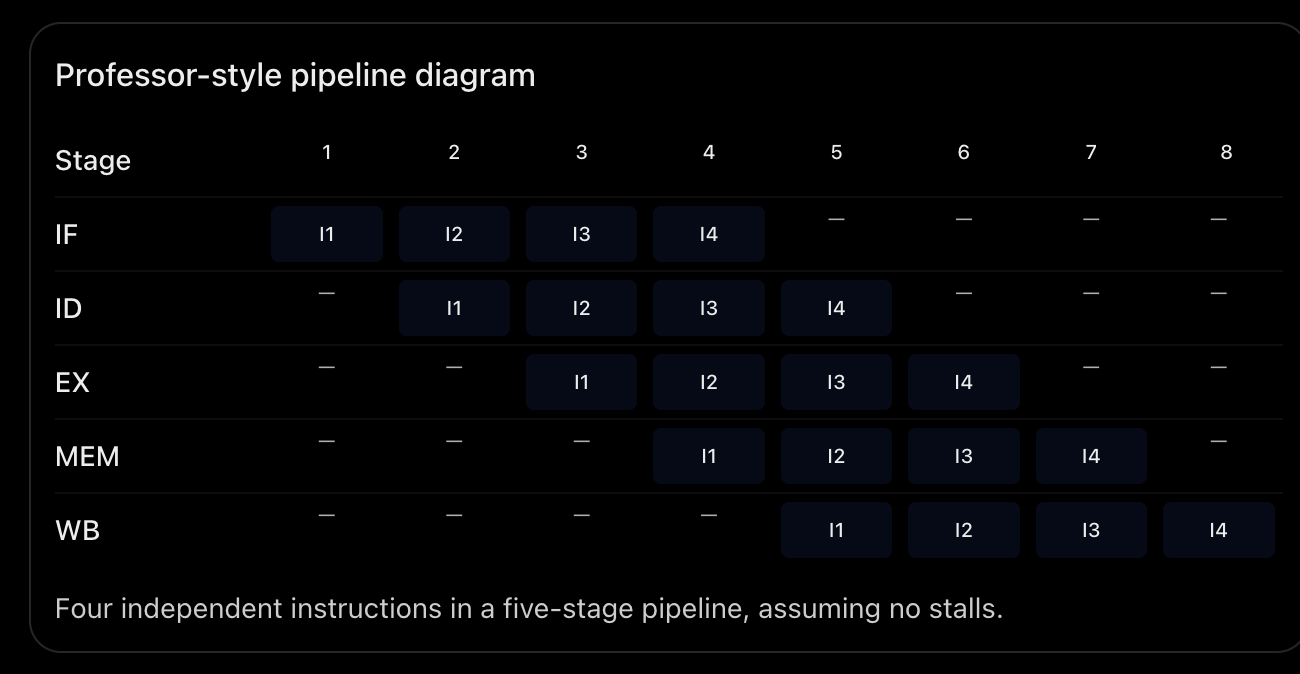

### 4.3 Let's Examine Cycle 4

| Stage | Instruction |
|---|---|
| IF | I4 |
| ID | I3 |
| EX | I2 |
| MEM | I1 |
| WB | Idle |

Four instructions are being processed simultaneously.

Notice that `I1` is the **oldest instruction**, so it's furthest along the pipeline.

---

## 5. What Is a Pipeline Bubble?

A **pipeline bubble** is an empty slot introduced into the instruction stream, often because an instruction must stall.

Consider:

```asm
lw  x5, 0(x10)
add x6, x5, x7
```

The `add` instruction needs the value loaded into `x5`.

But the load instruction obtains that data from memory at the **MEM stage**.

In a typical five-stage pipeline with forwarding, the immediately following `add` cannot use the loaded result in its originally scheduled EX cycle.

So the processor introduces a **one-cycle stall**.

### 5.1 Load-Use Hazard With One Stall

| Instruction | 1 | 2 | 3 | 4 | 5 | 6 | 7 |
|---|---|---|---|---|---|---|---|
| I1: `lw` | IF | ID | EX | MEM | WB | — | — |
| I2: `add` | — | IF | ID | Stall | EX | MEM | WB |

Instruction `I2` remains in Decode during cycle 4, while a bubble occupies EX.

Forwarding allows `I2` to execute in cycle 5.

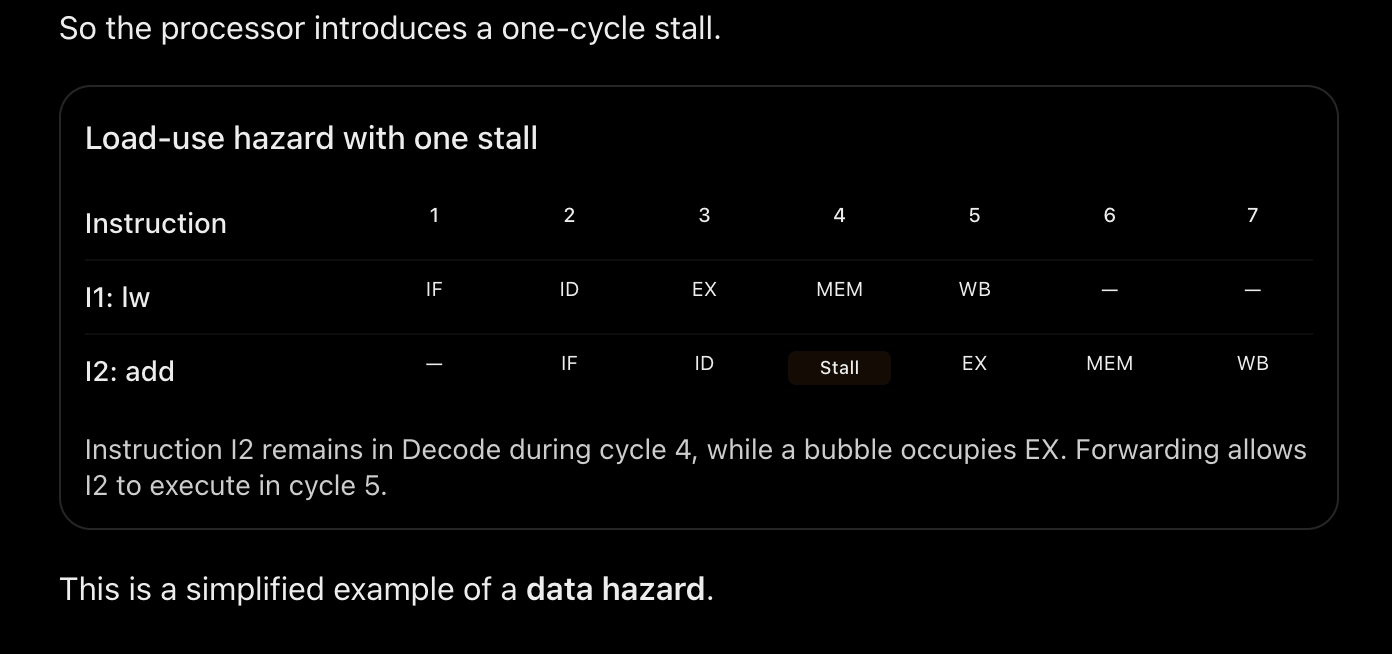

This is a simplified example of a **data hazard**.

Without appropriate hazard-handling circuitry, the second instruction could use an incorrect value.

The professor introduces bubbles here, then reserves detailed hazard classification and solutions for the following lectures.

---

## 6. What Do Hazards Do to Performance?

Recall:

$$
CPI=\frac{\text{Total Clock Cycles}}{\text{Instruction Count}}
$$

In an ideal single-issue pipeline, steady-state CPI approaches **1**.

If stalls introduce extra cycles:

$$
\text{Total Cycles}=n+k-1+\text{Stall Cycles}
$$

Therefore:

$$
\boxed{
CPI=\frac{n+k-1+\text{Stalls}}{n}
}
$$

As stalls increase:

- CPI increases.
- IPC decreases.

That is why the processor needs **hazard-detection and hazard-resolution mechanisms**.

---

## 7. Exam-Ready Lecture 23 Revision

| Term | Definition |
|---|---|
| Pipelining | Overlapping stages of different instructions |
| Uniform pipeline | Pipeline with approximately equal stage delays |
| Ideal pipeline | Simplified pipeline with no stalls and full stage utilization after filling |
| Pipeline register | Holds intermediate information between stages |
| Bubble | Empty pipeline slot, often caused by a stall |
| Pipeline hazard | Condition that prevents the next instruction from executing as scheduled |
| Instruction-level parallelism | Processing multiple instructions concurrently |

### Most Important Formulas

For $n$ instructions and $k$ stages, assuming equal clock periods and no stalls:

**Non-Pipelined Execution:**

$$
\boxed{T_{\text{nonpipe}}=nk\text{ cycles}}
$$

**Pipelined Execution:**

$$
\boxed{T_{\text{pipe}}=n+k-1\text{ cycles}}
$$

**Pipeline Speedup:**

$$
\boxed{\text{Speedup}=\frac{nk}{n+k-1}}
$$

**Maximum Ideal Speedup:**

For a large instruction count:

$$
\boxed{\text{Maximum ideal speedup}\rightarrow k}
$$

---


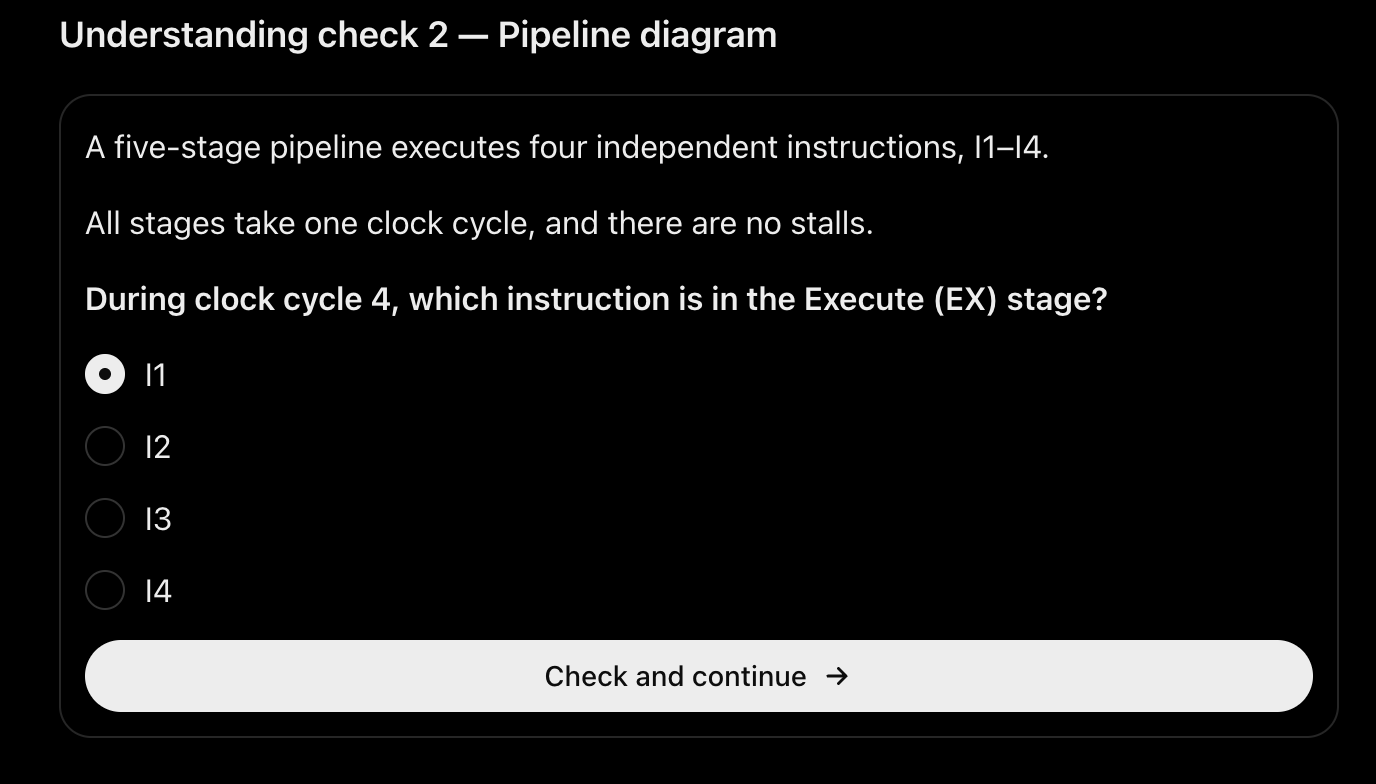
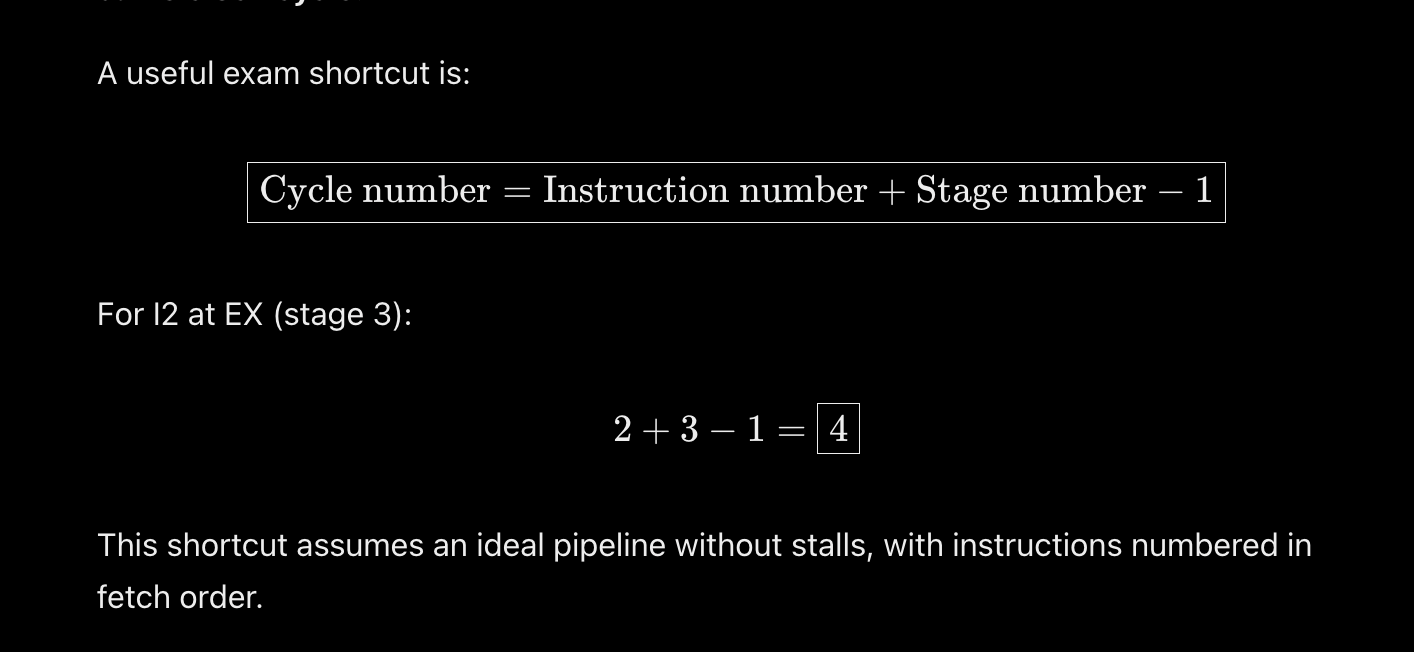